In [1]:
# 0. Import all the pythion libraries needed for this calculation

import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import micropip
await micropip.install('openpyxl')
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

The rest of these code cells calculate and plot your IC50 data.  Firstly we need to load the data, and define the variables based on that data which we will use in the rest of the calculations.

In [2]:
# 1. Load Data
file_path = 'IC50_Data2.xlsx'

try:
    df = pd.read_excel(file_path)
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please ensure the folder 'sample_data' and the file 'Oxalate_IC50.xlsx' exist.")
    exit()
except KeyError:
    print("Error: Data must contain columns 'conc' and 'rate'. Please check column names.")
    exit()

df = df.sort_values(by='conc').reset_index(drop=True)

X = df['conc'].values
Y = df['rate'].values

# Define Observed Data Limits for Dynamic Bounds and Plotting
Y_max_obs = Y.max()
Y_min_obs = Y.min()

# Crucial: Define X_min_plot as the smallest non-zero concentration to AVOID RuntimeWarning
X_non_zero = X[X > 0]
if len(X_non_zero) == 0:
    print("Error: Concentration data contains no positive values for log-scale plotting.")
    exit()

X_min_plot = X_non_zero.min()
X_max_plot = X.max()


Next, we need to define the "equation" that Python is going to use to calculate a best-fit line for our data.  The equation used is called a four-parameter logistic fit.  

The equation is

Y=(D+(A-D)/(1+(X/C)^B)

The "four parameters" referred to are:



*   A - The maximum value of Y (i.e. the top plateau for our sigmoidal curve)
*   D - The minimum value of Y (i.e. the bottom plateau)


*   C - The IC50 (the X-value (concentration) that gives a Y-value half way between max and min (this is what we're really interested in)
*   B - The gradient of the slope at IC50 (we can ignore this for our purposes, but the equation will calculate it anyway)





The equation used to fit your dose-response curve is:

$$
Y = D + \frac{A - D}{1 + \left(\frac{X}{IC_{50}}\right)^B}
$$

**Where the parameters represent:**

| Parameter | Meaning | Corresponds to |
| :---: | :--- | :--- |
| **Y** | Measured Enzyme Activity/Rate | Output |
| **X** | Inhibitor Concentration | Input |
| **A** | The top plateau of the sigmoidal curve| Fitted Max Rate |
| **D** | The bottom plateau of the sigmoidal curve | Fitted Min Rate |
| $\mathbf{IC_{50}}$ | Inflection Point **(called C in the python code)** | The concentration at half-maximal effect. |
| **B** | Hill Slope | Steepness of the curve. |

In [3]:
# 2. Define the Four-Parameter Logistic (4PL) Model
def four_param_logistic(X, A, B, C, D):
    """
    4PL sigmoidal function for inhibition curve fitting.
    A: Top, D: Bottom, C: IC50, B: Hill slope
    """
    return D + (A - D) / (1 + (X / C)**B)

Now we're going to estimate values of the parameters, based on the data we've given Python; and the boundaries that Python will allow the fitted values to lie between

In [4]:
# 3. Calculate Initial Guesses (p0) and Dynamic Bounds
A_guess = Y_max_obs
D_guess = Y_min_obs
mid_point = (A_guess + D_guess) / 2.0
idx = np.argmin(np.abs(Y - mid_point))
C_guess = X[idx]

if C_guess <= 0:
    C_guess = np.sqrt(X_min_plot * X_max_plot)

B_guess = 1.0
p0 = [A_guess, B_guess, C_guess, D_guess]

# Define Dynamic Bounds
lower_bounds = [Y_min_obs * 0.5, 0.1, X_min_plot / 10.0, Y_min_obs * 0.9]
upper_bounds = [Y_max_obs * 1.5, 10.0, X_max_plot * 10.0, Y_max_obs * 1.1]
bounds = (lower_bounds, upper_bounds)

Now that we've set our starting points, Python can carry on with finding a set of parameters that best-fits our experimental data.

In [5]:
# 4. Perform Curve Fitting
try:
    popt, pcov = curve_fit(four_param_logistic, X, Y, p0=p0, bounds=bounds)
    A_fit, B_fit, IC50_fit, D_fit = popt

    # R-squared and Standard Error calculation
    residuals = Y - four_param_logistic(X, *popt)
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((Y - np.mean(Y))**2)
    r_squared = 1 - (ss_res / ss_tot)
    perr = np.sqrt(np.diag(pcov))
    IC50_se = perr[2]

except RuntimeError:
    print("\nError: Optimal parameters not found for curve fitting.")
    IC50_fit, r_squared, IC50_se = np.nan, np.nan, np.nan

Assuming that has worked, and hasn't returned

*Error: Optimal parameters not found for curve fitting.*

then saved somewhere in the guts of the computer are values for all the parameters.  That's great, but we'd quite like to know what they are, and to see the line that corresponds to the equation at each value of X (i.e. a line of best fit).  The next block of code should return that for us.  It will also save the IC50 plot as a file in the "Content" folder (that's the same folder where the "sample_data" folder is found)


--- IC50 Calculation Results ---
Fitted IC50 (C): 1.808e-05 (M or unit of 'conc')
Standard Error of IC50: 1.571e-06
R-squared: 0.9939

Plot saved as 'IC50_Dose_Response_Fit.png'


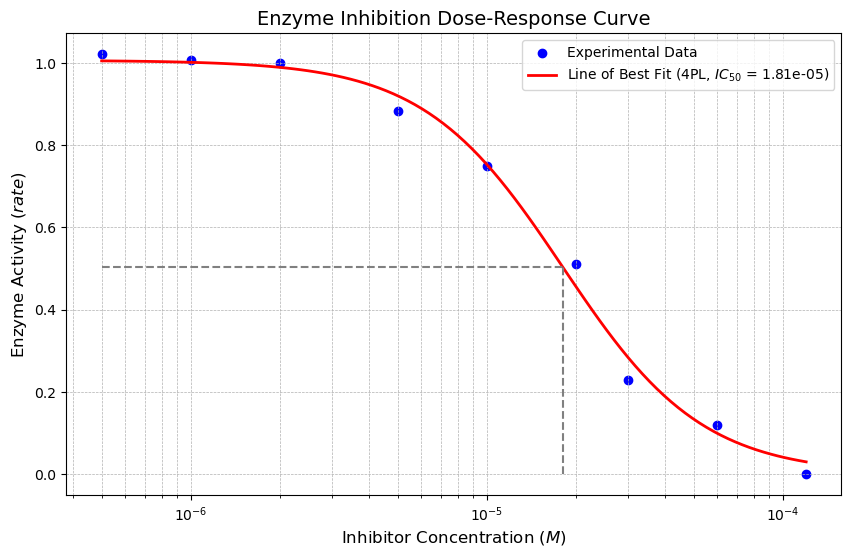

In [6]:
  # 5. Output Results and Plot
print("\n--- IC50 Calculation Results ---")
if not np.isnan(IC50_fit):
    print(f"Fitted IC50 (C): {IC50_fit:.3e} (M or unit of 'conc')")
    print(f"Standard Error of IC50: {IC50_se:.3e}")
    print(f"R-squared: {r_squared:.4f}")

    # Generate smooth curve data for plotting:
    # Uses X_min_plot (smallest non-zero concentration) for the log base
    X_fit = np.logspace(np.log10(X_min_plot), np.log10(X_max_plot), 100)
    Y_fit = four_param_logistic(X_fit, *popt)

    # Plotting
    plt.figure(figsize=(10, 6))

    # Scatter the experimental data points
    plt.scatter(X, Y, label='Experimental Data', color='blue', marker='o')

    # Line of Best Fit (Fitted 4PL Curve)
    # The 'r-' ensures a distinct red line.
    plt.plot(X_fit, Y_fit, 'r-', linewidth=2, label=f'Line of Best Fit (4PL, $\t{{IC}}_{{50}}$ = {IC50_fit:.2e})')

    # Draw lines for the IC50 point
    y_IC50 = four_param_logistic(IC50_fit, *popt)
    plt.hlines(y=y_IC50, xmin=X_min_plot, xmax=IC50_fit, color='gray', linestyle='--')
    plt.vlines(x=IC50_fit, ymin=D_fit, ymax=y_IC50, color='gray', linestyle='--')

    plt.xscale('log')
    plt.xlabel('Inhibitor Concentration ($\t{M}$)', fontsize=12)
    plt.ylabel('Enzyme Activity ($\t{rate}$)', fontsize=12)
    plt.title('Enzyme Inhibition Dose-Response Curve', fontsize=14)
    plt.legend(fontsize=10)
    plt.grid(True, which="both", ls="--", linewidth=0.5)

    # Save the plot
    plt.savefig('IC50_Dose_Response_Fit.png')
    print("\nPlot saved as 'IC50_Dose_Response_Fit.png'")

    # Show the plot interactively
    # This command is correct, but interactive display depends on your environment (e.g., must run in an IDE or notebook).
    plt.show()
else:
    print("IC50 calculation failed.")

# --- End of the IC50 Calculation Script ---